<a href="https://colab.research.google.com/github/rmoy1-clt/Intro-to-ML/blob/main/HW6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW6: Fully Connected Neural Networks


## 0. Setup

The neural networks are built with PyTorch (`nn.Sequential`) and trained with mini-batches and the Adam optimizer.

To keep the test set untouched until the end, 20% of the **training** set is held out as a validation set. The
validation set is used for the loss curves and for picking the architecture and number of epochs. The chosen network
is then retrained on the full training set and evaluated once on the test set. All scalers are fitted on training
data only.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, SVC
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
f32 = torch.float32

In [ ]:
def make_net(n_in, hidden, act):
    """Fully connected network: n_in -> hidden[0] -> hidden[1] -> ... -> 1"""
    layers, prev = [], n_in
    for h in hidden:
        layers += [nn.Linear(prev, h), act()]
        prev = h
    layers.append(nn.Linear(prev, 1))
    return nn.Sequential(*layers)

def train_net(model, loss_fn, X_tr, y_tr, X_va=None, y_va=None, lr=1e-3, batch_size=32, epochs=200, classify=False):
    """Mini-batch training with Adam. Records the loss (and accuracy) on the full training and validation sets each epoch."""
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            out_tr = model(X_tr)
            hist['train_loss'].append(loss_fn(out_tr, y_tr).item())
            if classify:
                hist['train_acc'].append(((out_tr > 0).float() == y_tr).float().mean().item())
            if X_va is not None:
                out_va = model(X_va)
                hist['val_loss'].append(loss_fn(out_va, y_va).item())
                if classify:
                    hist['val_acc'].append(((out_va > 0).float() == y_va).float().mean().item())
    return hist

---
# Problem 1: Housing price prediction

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/My Drive/Intro To ML/Datasets/Housing.csv'
df = pd.read_csv(file_path)
print(df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [ ]:
BINARY = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for c in BINARY:
    df[c] = df[c].map({'yes': 1, 'no': 0})
furn = pd.get_dummies(df['furnishingstatus'], prefix='furn', drop_first=True).astype(int)
df = pd.concat([df, furn], axis=1)
FEATS = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
         'hotwaterheating', 'airconditioning', 'parking', 'prefarea'] + list(furn.columns)
X = df[FEATS].values.astype(float)
y = df['price'].values.astype(float)
print(len(FEATS), 'input features:', FEATS)

# same 80/20 train/test split as HW2 and HW5
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(df))
k = int(np.floor(0.8 * len(df)))
TR, TE = perm[:k], perm[k:]
Xh_tr, Xh_te, yh_tr, yh_te = X[TR], X[TE], y[TR], y[TE]

# validation set = 20% of the training set (only used to pick the network and plot the curves)
sub_tr, sub_va = train_test_split(np.arange(len(TR)), test_size=0.2, random_state=SEED)
print('train:', len(TR), ' (fit:', len(sub_tr), ' validation:', len(sub_va), ')   test:', len(TE))

13 input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furn_semi-furnished', 'furn_unfurnished']
train: 436  (fit: 348  validation: 88 )   test: 109


In [ ]:
def scale_xy(Xa, ya, Xb, yb):
    """Standardize inputs and price with statistics from (Xa, ya) only. Returns float32 tensors."""
    sx, sy = StandardScaler().fit(Xa), StandardScaler().fit(ya.reshape(-1, 1))
    t = lambda a: torch.tensor(a, dtype=f32)
    return (t(sx.transform(Xa)), t(sy.transform(ya.reshape(-1, 1))),
            t(sx.transform(Xb)), t(sy.transform(yb.reshape(-1, 1))), sy)

def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

## 1.a Neural network development


In [ ]:
Xf, yf, Xv, yv, _ = scale_xy(Xh_tr[sub_tr], yh_tr[sub_tr], Xh_tr[sub_va], yh_tr[sub_va])

configs = {'[32, 16] ReLU':     ([32, 16], nn.ReLU),
           '[64, 32] ReLU':     ([64, 32], nn.ReLU),
           '[64, 32] Tanh':     ([64, 32], nn.Tanh),
           '[128, 64, 32] ReLU': ([128, 64, 32], nn.ReLU)}
EPOCHS_H = 300
hist_h = {}
for name, (hidden, act) in configs.items():
    torch.manual_seed(SEED)
    net = make_net(Xf.shape[1], hidden, act)
    hist_h[name] = train_net(net, nn.MSELoss(), Xf, yf, Xv, yv, lr=1e-3, batch_size=32, epochs=EPOCHS_H)

rows = []
for name, h in hist_h.items():
    best_ep = int(np.argmin(h['val_loss'])) + 1
    rows.append({'Network': name, 'Best val loss': min(h['val_loss']), 'at epoch': best_ep,
                 'Val loss (epoch 300)': h['val_loss'][-1], 'Train loss (epoch 300)': h['train_loss'][-1]})
sel_h = pd.DataFrame(rows).set_index('Network')
print(sel_h.round(4))

                    Best val loss  at epoch  Val loss (epoch 300)  \
Network                                                             
[32, 16] ReLU              0.3141        25                0.4751   
[64, 32] ReLU              0.3120         9                0.4894   
[64, 32] Tanh              0.2927        35                0.4343   
[128, 64, 32] ReLU         0.2736        17                0.3925   

                    Train loss (epoch 300)  
Network                                     
[32, 16] ReLU                       0.0302  
[64, 32] ReLU                       0.0128  
[64, 32] Tanh                       0.0232  
[128, 64, 32] ReLU                  0.0067  


selected network: [128, 64, 32] ReLU   epochs: 17


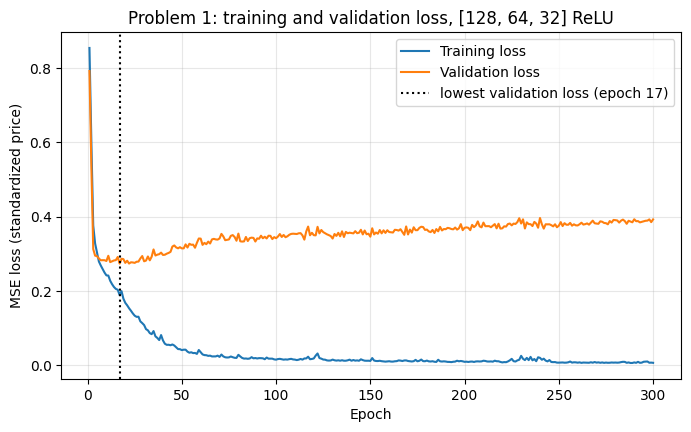

In [ ]:
BEST_H = sel_h['Best val loss'].idxmin()
EP_H = int(sel_h.loc[BEST_H, 'at epoch'])
print('selected network:', BEST_H, '  epochs:', EP_H)

h = hist_h[BEST_H]
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, EPOCHS_H + 1), h['train_loss'], label='Training loss')
plt.plot(range(1, EPOCHS_H + 1), h['val_loss'], label='Validation loss')
plt.axvline(EP_H, color='k', ls=':', label=f'lowest validation loss (epoch {EP_H})')
plt.xlabel('Epoch'); plt.ylabel('MSE loss (standardized price)')
plt.title(f'Problem 1: training and validation loss, {BEST_H}')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
# Retrain the selected network on the full training set for EP_H epochs, then evaluate on the test set
Xa, ya, Xt, yt, sy_h = scale_xy(Xh_tr, yh_tr, Xh_te, yh_te)
torch.manual_seed(SEED)
hidden, act = configs[BEST_H]
net_h = make_net(Xa.shape[1], hidden, act)
train_net(net_h, nn.MSELoss(), Xa, ya, lr=1e-3, batch_size=32, epochs=EP_H)
print(net_h)

net_h.eval()
with torch.no_grad():
    pred_nn = sy_h.inverse_transform(net_h(Xt).numpy()).ravel()
res_nn_h = reg_metrics(yh_te, pred_nn)
for k_, v in res_nn_h.items():
    print(f'{k_:<5} {v:,.4f}')

Sequential(
  (0): Linear(in_features=13, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
MSE   1,250,732,676,376.2666
RMSE  1,118,361.6036
R2    0.6454


## 1.b Comparison with Linear Regression and SVR


In [ ]:
def gradient_descent(Xtr, ytr, alpha=0.1, n_iter=10000):
    Xb = np.hstack([np.ones((Xtr.shape[0], 1)), Xtr])
    theta = np.zeros(Xb.shape[1])
    m = len(ytr)
    for _ in range(n_iter):
        theta -= alpha * (1.0 / m) * (Xb.T @ (Xb @ theta - ytr))
    return theta

sx_lr = StandardScaler().fit(Xh_tr)
theta_lr = gradient_descent(sx_lr.transform(Xh_tr), yh_tr)
pred_lr = np.hstack([np.ones((len(Xh_te), 1)), sx_lr.transform(Xh_te)]) @ theta_lr
res_lr_h = reg_metrics(yh_te, pred_lr)

grid = [{'kernel': ['linear'], 'C': [0.1, 1, 10]},
        {'kernel': ['poly'], 'C': [0.1, 1, 10], 'degree': [2, 3], 'coef0': [1]},
        {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': [0.01, 0.1, 'scale']}]
gs = GridSearchCV(SVR(), grid, cv=5, scoring='r2').fit(Xa.numpy(), ya.numpy().ravel())
print('best SVR:', gs.best_params_)
pred_svr = sy_h.inverse_transform(gs.predict(Xt.numpy()).reshape(-1, 1)).ravel()
res_svr_h = reg_metrics(yh_te, pred_svr)

comp_h = pd.DataFrame({'Neural network': res_nn_h, 'Linear regression (HW2 GD)': res_lr_h,
                       f'SVR ({gs.best_params_["kernel"]})': res_svr_h}).T
pd.options.display.float_format = '{:,.4f}'.format
print(comp_h)

best SVR: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
                                              MSE           RMSE     R2
Neural network             1,250,732,676,376.2666 1,118,361.6036 0.6454
Linear regression (HW2 GD) 1,088,775,887,231.4448 1,043,444.2425 0.6914
SVR (rbf)                  1,109,324,082,335.1648 1,053,244.5501 0.6855


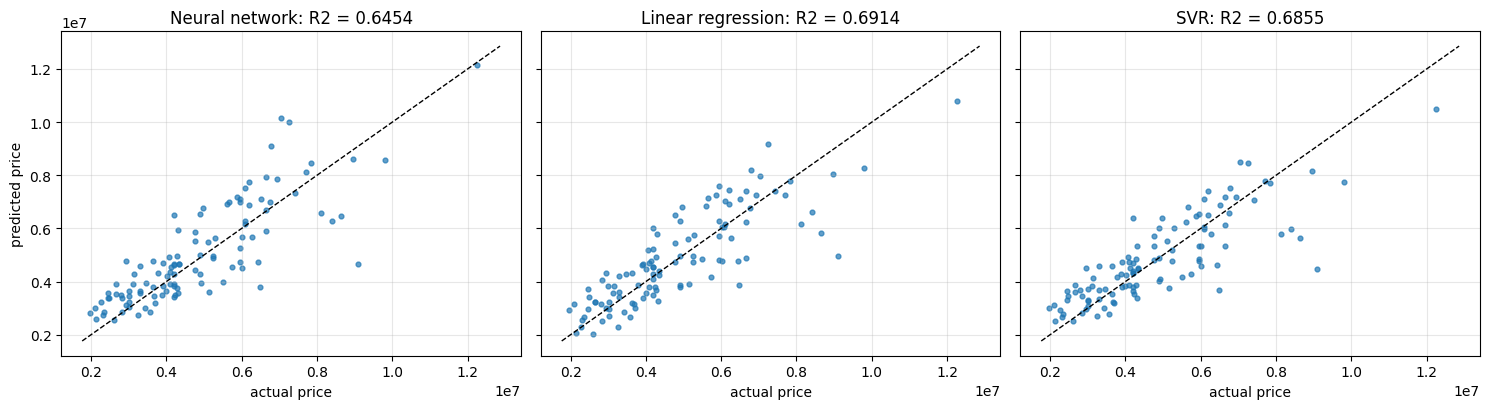

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
lims = [yh_te.min() * 0.9, yh_te.max() * 1.05]
for ax, (name, p) in zip(axes, [('Neural network', pred_nn), ('Linear regression', pred_lr), ('SVR', pred_svr)]):
    ax.scatter(yh_te, p, s=12, alpha=0.7)
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_title(f'{name}: R2 = {r2_score(yh_te, p):.4f}')
    ax.set_xlabel('actual price'); ax.grid(alpha=0.3)
axes[0].set_ylabel('predicted price')
plt.tight_layout(); plt.show()

---
# Problem 2: Breast cancer classification


In [ ]:
cancer = load_breast_cancer()
Xc = cancer.data
yc = 1 - cancer.target                     # 1 = malignant, 0 = benign
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.2, random_state=SEED)
sub_tr_c, sub_va_c = train_test_split(np.arange(len(Xc_tr)), test_size=0.2, random_state=SEED)
print('train:', len(Xc_tr), ' (fit:', len(sub_tr_c), ' validation:', len(sub_va_c), ')   test:', len(Xc_te))

def scale_x(Xa, Xb):
    s = StandardScaler().fit(Xa)
    return torch.tensor(s.transform(Xa), dtype=f32), torch.tensor(s.transform(Xb), dtype=f32)

col = lambda v: torch.tensor(v.reshape(-1, 1), dtype=f32)

def cls_report(y_true, y_pred):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred), 'F1 score': f1_score(y_true, y_pred)}

train: 455  (fit: 364  validation: 91 )   test: 114


## 2.a Neural network development


In [ ]:
Xcf, Xcv = scale_x(Xc_tr[sub_tr_c], Xc_tr[sub_va_c])
ycf, ycv = col(yc_tr[sub_tr_c]), col(yc_tr[sub_va_c])

configs_c = {'[16, 8] ReLU':  ([16, 8], nn.ReLU),
             '[32, 16] ReLU': ([32, 16], nn.ReLU),
             '[32, 16] Tanh': ([32, 16], nn.Tanh),
             '[64, 32] ReLU': ([64, 32], nn.ReLU)}
EPOCHS_C = 100
hist_c = {}
for name, (hidden, act) in configs_c.items():
    torch.manual_seed(SEED)
    net = make_net(30, hidden, act)
    hist_c[name] = train_net(net, nn.BCEWithLogitsLoss(), Xcf, ycf, Xcv, ycv,
                             lr=1e-3, batch_size=32, epochs=EPOCHS_C, classify=True)

rows = []
for name, h in hist_c.items():
    best_ep = int(np.argmin(h['val_loss'])) + 1
    rows.append({'Network': name, 'Best val loss': min(h['val_loss']), 'at epoch': best_ep,
                 'Val acc at that epoch': h['val_acc'][best_ep - 1], 'Val acc (epoch 100)': h['val_acc'][-1]})
sel_c = pd.DataFrame(rows).set_index('Network')
print(sel_c.round(4))

               Best val loss  at epoch  Val acc at that epoch  \
Network                                                         
[16, 8] ReLU          0.1486        28                 0.9670   
[32, 16] ReLU         0.1410        16                 0.9670   
[32, 16] Tanh         0.1268        66                 0.9560   
[64, 32] ReLU         0.1388        11                 0.9670   

               Val acc (epoch 100)  
Network                             
[16, 8] ReLU                0.9670  
[32, 16] ReLU               0.9670  
[32, 16] Tanh               0.9560  
[64, 32] ReLU               0.9670  


selected network: [32, 16] Tanh   epochs: 66


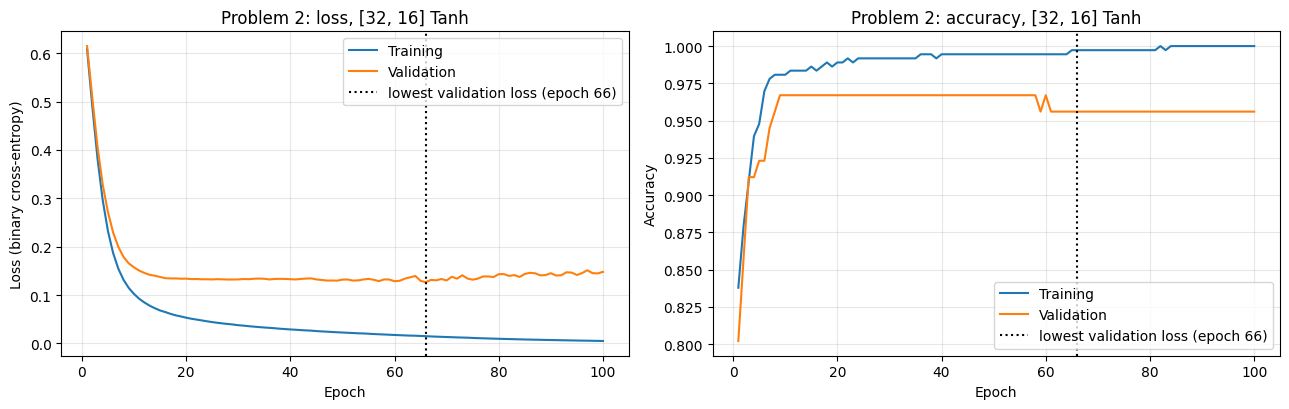

In [ ]:
BEST_C = sel_c['Best val loss'].idxmin()
EP_C = int(sel_c.loc[BEST_C, 'at epoch'])
print('selected network:', BEST_C, '  epochs:', EP_C)

h = hist_c[BEST_C]
ep = range(1, EPOCHS_C + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(ep, h['train_loss'], label='Training'); ax[0].plot(ep, h['val_loss'], label='Validation')
ax[0].set_ylabel('Loss (binary cross-entropy)'); ax[0].set_title(f'Problem 2: loss, {BEST_C}')
ax[1].plot(ep, h['train_acc'], label='Training'); ax[1].plot(ep, h['val_acc'], label='Validation')
ax[1].set_ylabel('Accuracy'); ax[1].set_title(f'Problem 2: accuracy, {BEST_C}')
for a in ax:
    a.axvline(EP_C, color='k', ls=':', label=f'lowest validation loss (epoch {EP_C})')
    a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

Sequential(
  (0): Linear(in_features=30, out_features=32, bias=True)
  (1): Tanh()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): Tanh()
  (4): Linear(in_features=16, out_features=1, bias=True)
)
Accuracy   0.9825
Precision  0.9767
Recall     0.9767
F1 score   0.9767


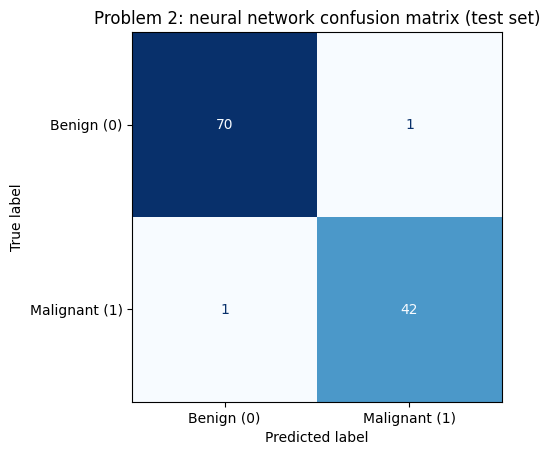

In [ ]:
# Retrain the selected network on the full training set for EP_C epochs, then evaluate on the test set
Xca, Xct = scale_x(Xc_tr, Xc_te)
torch.manual_seed(SEED)
hidden, act = configs_c[BEST_C]
net_c = make_net(30, hidden, act)
train_net(net_c, nn.BCEWithLogitsLoss(), Xca, col(yc_tr), lr=1e-3, batch_size=32, epochs=EP_C, classify=True)
print(net_c)

net_c.eval()
with torch.no_grad():
    yp_nn = (net_c(Xct) > 0).int().numpy().ravel()
res_nn_c = cls_report(yc_te, yp_nn)
for k_, v in res_nn_c.items():
    print(f'{k_:<10} {v:.4f}')

ConfusionMatrixDisplay(confusion_matrix(yc_te, yp_nn), display_labels=['Benign (0)', 'Malignant (1)']).plot(
    cmap='Blues', colorbar=False)
plt.title('Problem 2: neural network confusion matrix (test set)'); plt.show()

## 2.b Comparison with Logistic Regression and SVM


In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def train_logistic(X, y, lr=0.1, n_iter=2000):
    Xb = np.hstack([np.ones((X.shape[0], 1)), X])
    theta = np.zeros(Xb.shape[1])
    for _ in range(n_iter):
        theta -= lr * Xb.T @ (sigmoid(Xb @ theta) - y) / len(y)
    return theta

sc_c = StandardScaler().fit(Xc_tr)                 # same scaling as HW3 / HW4, in float64
Xca_np, Xct_np = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
theta_log = train_logistic(Xca_np, yc_tr)
yp_log = (sigmoid(np.hstack([np.ones((len(Xct_np), 1)), Xct_np]) @ theta_log) >= 0.5).astype(int)

svm = SVC(kernel='rbf', C=1.0).fit(Xca_np, yc_tr)
yp_svm = svm.predict(Xct_np)

comp_c = pd.DataFrame({'Neural network': res_nn_c, 'Logistic regression (HW3 GD)': cls_report(yc_te, yp_log),
                       'SVM (RBF)': cls_report(yc_te, yp_svm)}).T
print((comp_c * 100).round(2))

                              Accuracy  Precision  Recall  F1 score
Neural network                 98.2500    97.6700 97.6700   97.6700
Logistic regression (HW3 GD)   99.1200   100.0000 97.6700   98.8200
SVM (RBF)                      98.2500   100.0000 95.3500   97.6200


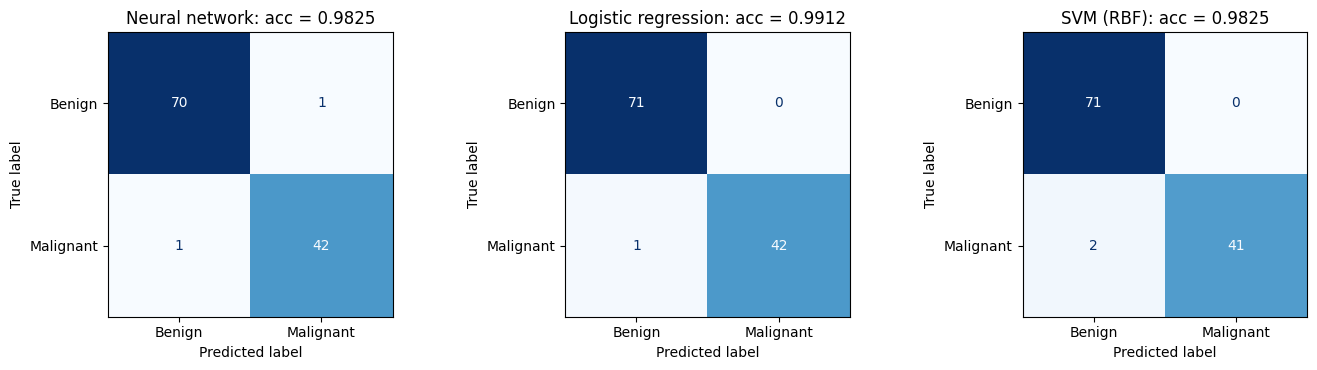

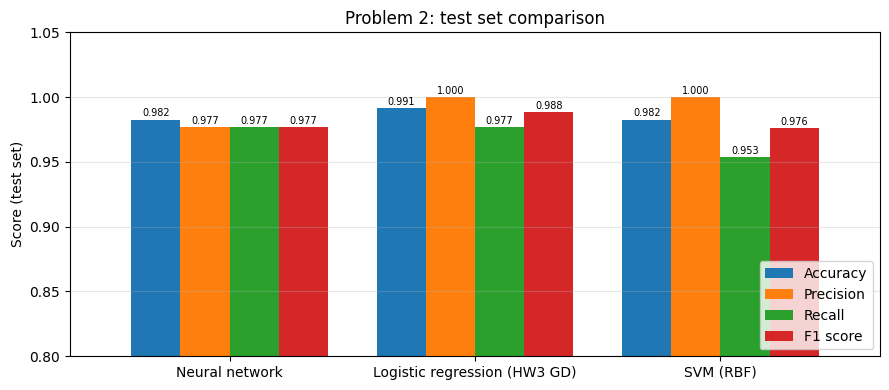

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, p) in zip(axes, [('Neural network', yp_nn), ('Logistic regression', yp_log), ('SVM (RBF)', yp_svm)]):
    ConfusionMatrixDisplay(confusion_matrix(yc_te, p), display_labels=['Benign', 'Malignant']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}: acc = {accuracy_score(yc_te, p):.4f}')
plt.tight_layout(); plt.show()

ax = comp_c.plot(kind='bar', figsize=(9, 4), width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=7, padding=1)
ax.set_ylim(0.8, 1.05); ax.set_ylabel('Score (test set)')
ax.set_title('Problem 2: test set comparison')
plt.xticks(rotation=0); plt.legend(loc='lower right'); plt.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()